In [33]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

Step-01
Data Gathering (DATASET)

In [34]:
df=pd.read_csv('/content/house_prices.csv', on_bad_lines='skip')

EDA (Exploratory Data Analysis)


In [35]:
df.head()

,Index,Title,Description,Amount(in rupees),Price (in rupees),location,Carpet Area,Status,Floor,Transaction,...,facing,overlooking,Society,Bathroom,Balcony,Car Parking,Ownership,Super Area,Dimensions,Plot Area
0,0,1 BHK Ready to Occupy Flat for sale in Srushti...,"Bhiwandi, Thane has an attractive 1 BHK Flat f...",42 Lac,6000.0,thane,500 sqft,Ready to Move,10 out of 11,Resale,...,NaN,NaN,Srushti Siddhi Mangal Murti Complex,1,2,NaN,NaN,NaN,NaN,NaN
1,1,2 BHK Ready to Occupy Flat for sale in Dosti V...,One can find this stunning 2 BHK flat for sale...,98 Lac,13799.0,thane,473 sqft,Ready to Move,3 out of 22,Resale,...,East,Garden/Park,Dosti Vihar,2,NaN,1 Open,Freehold,NaN,NaN,NaN
2,2,2 BHK Ready to Occupy Flat for sale in Sunrise...,Up for immediate sale is a 2 BHK apartment in ...,1.40 Cr,17500.0,thane,779 sqft,Ready to Move,10 out of 29,Resale,...,East,Garden/Park,Sunrise by Kalpataru,2,NaN,1 Covered,Freehold,NaN,NaN,NaN
3,3,1 BHK Ready to Occupy Flat for sale Kasheli,This beautiful 1 BHK Flat is available for sal...,25 Lac,NaN,thane,530 sqft,Ready to Move,1 out of 3,Resale,...,NaN,NaN,NaN,1,1,NaN,NaN,NaN,NaN,NaN
4,4,2 BHK Ready to Occupy Flat for sale in TenX Ha...,"This lovely 2 BHK Flat in Pokhran Road, Thane ...",1.60 Cr,18824.0,thane,635 sqft,Ready to Move,20 out of 42,Resale,...,West,"Garden/Park, Main Road",TenX Habitat Raymond Realty,2,NaN,1 Covered,Co-operative Society,NaN,NaN,NaN


In [36]:
df.shape

(116046, 21)

In [37]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 116046 entries, 0 to 116045
Data columns (total 21 columns):
 #   Column             Non-Null Count   Dtype  
---  ------             --------------   -----  
 0   Index              116046 non-null  int64  
 1   Title              116046 non-null  object 
 2   Description        113685 non-null  object 
 3   Amount(in rupees)  116046 non-null  object 
 4   Price (in rupees)  104807 non-null  float64
 5   location           116046 non-null  object 
 6   Carpet Area        58861 non-null   object 
 7   Status             115680 non-null  object 
 8   Floor              110465 non-null  object 
 9   Transaction        116004 non-null  object 
 10  Furnishing         113901 non-null  object 
 11  facing             69955 non-null   object 
 12  overlooking        61232 non-null   object 
 13  Society            43549 non-null   object 
 14  Bathroom           115599 non-null  object 
 15  Balcony            80977 non-null   object 
 16  Ca

In [38]:
df.isnull().sum()

,0
Index,0
Title,0
Description,2361
Amount(in rupees),0
Price (in rupees),11239
location,0
Carpet Area,57185
Status,366
Floor,5581
Transaction,42


In [39]:
df.describe()

,Index,Price (in rupees),Dimensions,Plot Area
count,116046.000000,104807.000000,0.0,0.0
mean,58022.500000,7484.596983,NaN,NaN
std,33499.739006,4866.153237,NaN,NaN
min,0.000000,17.000000,NaN,NaN
25%,29011.250000,4500.000000,NaN,NaN
50%,58022.500000,6173.000000,NaN,NaN
75%,87033.750000,8614.000000,NaN,NaN
max,116045.000000,84619.000000,NaN,NaN


In [40]:
df.duplicated().sum()

np.int64(0)

In [41]:
df['Plot Area'].isnull().sum()

np.int64(116046)

In [42]:
df['Dimensions'].isnull().sum()

np.int64(116046)

In [43]:
df.drop(columns=['Plot Area','Dimensions'], inplace=True)

In [44]:
df.shape

(116046, 19)

In [45]:
missing=df.isnull().sum()
missing_percent=(missing/len(df))*100
missing_table = pd.DataFrame({
    "Missing Count": missing,
    "Missing Percentage": missing_percent
})

missing_table = missing_table.sort_values(
    by="Missing Percentage",
    ascending=False
)
print(missing_table)

                   Missing Count  Missing Percentage
Society                    72497           62.472640
Car Parking                65935           56.817986
Super Area                 59604           51.362391
Carpet Area                57185           49.277873
overlooking                54814           47.234717
facing                     46091           39.717870
Ownership                  45206           38.955242
Balcony                    35069           30.219913
Price (in rupees)          11239            9.684953
Floor                       5581            4.809300
Description                 2361            2.034538
Furnishing                  2145            1.848405
Bathroom                     447            0.385192
Status                       366            0.315392
Transaction                   42            0.036193
Title                          0            0.000000
Index                          0            0.000000
Amount(in rupees)              0            0.

In [46]:
df.head()

,Index,Title,Description,Amount(in rupees),Price (in rupees),location,Carpet Area,Status,Floor,Transaction,Furnishing,facing,overlooking,Society,Bathroom,Balcony,Car Parking,Ownership,Super Area
0,0,1 BHK Ready to Occupy Flat for sale in Srushti...,"Bhiwandi, Thane has an attractive 1 BHK Flat f...",42 Lac,6000.0,thane,500 sqft,Ready to Move,10 out of 11,Resale,Unfurnished,NaN,NaN,Srushti Siddhi Mangal Murti Complex,1,2,NaN,NaN,NaN
1,1,2 BHK Ready to Occupy Flat for sale in Dosti V...,One can find this stunning 2 BHK flat for sale...,98 Lac,13799.0,thane,473 sqft,Ready to Move,3 out of 22,Resale,Semi-Furnished,East,Garden/Park,Dosti Vihar,2,NaN,1 Open,Freehold,NaN
2,2,2 BHK Ready to Occupy Flat for sale in Sunrise...,Up for immediate sale is a 2 BHK apartment in ...,1.40 Cr,17500.0,thane,779 sqft,Ready to Move,10 out of 29,Resale,Unfurnished,East,Garden/Park,Sunrise by Kalpataru,2,NaN,1 Covered,Freehold,NaN
3,3,1 BHK Ready to Occupy Flat for sale Kasheli,This beautiful 1 BHK Flat is available for sal...,25 Lac,NaN,thane,530 sqft,Ready to Move,1 out of 3,Resale,Unfurnished,NaN,NaN,NaN,1,1,NaN,NaN,NaN
4,4,2 BHK Ready to Occupy Flat for sale in TenX Ha...,"This lovely 2 BHK Flat in Pokhran Road, Thane ...",1.60 Cr,18824.0,thane,635 sqft,Ready to Move,20 out of 42,Resale,Unfurnished,West,"Garden/Park, Main Road",TenX Habitat Raymond Realty,2,NaN,1 Covered,Co-operative Society,NaN


In [47]:
df["Title"].head(10)

,Title
0,1 BHK Ready to Occupy Flat for sale in Srushti...
1,2 BHK Ready to Occupy Flat for sale in Dosti V...
2,2 BHK Ready to Occupy Flat for sale in Sunrise...
3,1 BHK Ready to Occupy Flat for sale Kasheli
4,2 BHK Ready to Occupy Flat for sale in TenX Ha...
5,1 BHK Ready to Occupy Flat for sale in Virat A...
6,1 BHK Ready to Occupy Flat for sale Mumbra
7,1 BHK Ready to Occupy Flat for sale Kalwa
8,1 BHK Ready to Occupy Flat for sale Kalwa
9,3 BHK Ready to Occupy Flat for sale in Pride P...


In [48]:
df["Title"].isnull().sum()

np.int64(0)

In [49]:
df[["Amount(in rupees)", "Price (in rupees)"]].head(20)

,Amount(in rupees),Price (in rupees)
0,42 Lac,6000.0
1,98 Lac,13799.0
2,1.40 Cr,17500.0
3,25 Lac,NaN
4,1.60 Cr,18824.0
5,45 Lac,6618.0
6,16.5 Lac,2538.0
7,60 Lac,10435.0
8,60 Lac,10000.0
9,1.60 Cr,11150.0


In [50]:
df[["Amount(in rupees)", "Price (in rupees)", "Carpet Area"]].head(20)

,Amount(in rupees),Price (in rupees),Carpet Area
0,42 Lac,6000.0,500 sqft
1,98 Lac,13799.0,473 sqft
2,1.40 Cr,17500.0,779 sqft
3,25 Lac,NaN,530 sqft
4,1.60 Cr,18824.0,635 sqft
5,45 Lac,6618.0,NaN
6,16.5 Lac,2538.0,550 sqft
7,60 Lac,10435.0,NaN
8,60 Lac,10000.0,NaN
9,1.60 Cr,11150.0,900 sqft


In [51]:
df["location"].value_counts()

,count
location,
bangalore,24030
kolkata,22380
gurgaon,20070
ahmedabad,12750
hyderabad,12300
chennai,10500
jaipur,8490
mumbai,1860
thane,972


In [52]:
df["Carpet Area"].value_counts().head(20)

,count
Carpet Area,
900 sqft,2995
1000 sqft,2817
600 sqft,1919
1300 sqft,1336
950 sqft,1327
1700 sqft,1289
1450 sqft,1013
700 sqft,986
3600 sqft,975


In [53]:
df["Carpet Area"].tail(20)

,Carpet Area
116026,1125 sqft
116027,800 sqft
116028,900 sqft
116029,1800 sqft
116030,990 sqft
116031,600 sqft
116032,630 sqft
116033,NaN
116034,2000 sqft
116035,2200 sqft


In [54]:
# Extract numeric values only using a raw string for the regex to avoid SyntaxWarnings
df["Carpet Area"].str.extract(r'(\d+\.?\d*)').astype(float).describe()

,0
count,58861.000000
mean,1236.343674
std,1246.027381
min,2.000000
25%,750.000000
50%,1000.000000
75%,1470.000000
max,194936.000000


In [55]:
df["Carpet Area"].str.extract(r'(\d+\.?\d*)').astype(float).squeeze().nlargest(20)

,0
50895,194936.0
82876,107806.0
41560,43500.0
72727,30000.0
70509,23000.0
52067,15500.0
115852,15000.0
51910,11500.0
16699,11000.0
85161,9000.0


In [56]:
# Get the indices of the 5 largest Carpet Area values and display their details
top_5_indices = df["Carpet Area"].str.extract(r'(\d+\.?\d*)').astype(float).squeeze().nlargest(5).index
df.loc[top_5_indices, ["Title", "Amount(in rupees)", "Carpet Area", "location"]]

,Title,Amount(in rupees),Carpet Area,location
50895,3 BHK Ready to Occupy Flat for sale in TARC Ma...,2.60 Cr,194936 sqft,gurgaon
82876,3 BHK Ready to Occupy Flat for sale in Seven H...,68 Lac,107806 sqft,jaipur
41560,3 BHK Ready to Occupy Flat for sale Thiruvanmiyur,1.90 Cr,43500 sqft,chennai
72727,6 BHK Ready to Occupy Flat for sale Gachibowli,20 Cr,30000 sqft,hyderabad
70509,> 10 BHK Ready to Occupy Flat for sale Fatehnagar,Call for Price,23000 sqft,hyderabad


In [57]:
carpet = df["Carpet Area"].str.extract(r'(\d+\.?\d*)').astype(float)[0]

print("Above 5,000:", (carpet > 5000).sum())
print("Above 10,000:", (carpet > 10000).sum())
print("Above 20,000:", (carpet > 20000).sum())

Above 5,000: 59
Above 10,000: 9
Above 20,000: 5


In [58]:
print("2000-5000 sqft:", ((carpet > 2000) & (carpet <= 5000)).sum())

2000-5000 sqft: 6005


In [59]:
df.loc[carpet > 5000,
       ["Title", "Amount(in rupees)", "Carpet Area", "location"]].sort_values(
           "Carpet Area", ascending=False
       ).head(20)


,Title,Amount(in rupees),Carpet Area,location
85161,3 BHK Ready to Occupy Flat for sale Rani Sati ...,75 Lac,9000 sqft,jaipur
72189,5 BHK Ready to Occupy Flat for sale Financial ...,15 Cr,8720 sqft,hyderabad
72932,6 BHK Ready to Occupy Flat for sale in Myscape...,15 Cr,8700 sqft,hyderabad
2997,4 BHK Ready to Occupy Flat for sale in Verante...,11 Cr,8000 sqft,ahmedabad
3223,6 BHK Ready to Occupy Flat for sale in Verante...,11 Cr,8000 sqft,ahmedabad
51750,5 BHK Ready to Occupy Flat for sale in Pioneer...,14 Cr,8000 sqft,gurgaon
50931,4 BHK Ready to Occupy Flat for sale in Ambienc...,11 Cr,7500 sqft,gurgaon
50187,5 BHK Ready to Occupy Flat for sale in Ambienc...,14 Cr,7500 sqft,gurgaon
52101,5 BHK Ready to Occupy Flat for sale in Ambienc...,14.50 Cr,7500 sqft,gurgaon
51968,4 BHK Ready to Occupy Flat for sale in Luxury ...,7.45 Cr,7425 sqft,gurgaon


In [60]:
df["Carpet Area"].dropna().str.extract(r'([A-Za-z]+)')[0].value_counts()


,count
0,
sqft,56146
sqyrd,2349
sqm,364
acre,2


In [61]:
#We should inspect the actual values for the rare units.
df[df["Carpet Area"].str.contains(
    "marla|acre|kanal|ground|bigha|cent",
    case=False,
    na=False
)][["Carpet Area", "location", "Title"]]


,Carpet Area,location,Title
93644,1500 acre,kolkata,3 BHK Ready to Occupy Flat for sale in The Nes...
113787,2 acre,lucknow,6 BHK Ready to Occupy Flat for sale in LDA PAR...


# ABOUT CARPET AREA
Our EDA conclusion for Carpet Area

We now know:

It should ultimately become a numeric feature.
Most values are sqft, which is straightforward.
sqyrd and sqm can be converted to sqft.
The extremely rare units such as acre, bigha, kanal, etc. are unreliable in this context.
There are also extreme numeric outliers such as 709,222 sqft.
43.02% of the column is missing, so missing-value treatment will matter.

In [62]:
df["Status"].value_counts(dropna=False)

,count
Status,
Ready to Move,115680
NaN,366


#ANALYSIS ABOUT DATASET


1.   column named Plot Area and Dimensions are completly empty --> We can remove them from the dataset
2.   Target column AMOUNT but the problem is it is stored in '43 lac' convert 4300000.

3. location → useful feature ✅
4. In carpet area we have many units as sqrd,marla acre and bigha
5. It has excellent data completeness, but zero useful variation So at the modeling stage, we'll most likely drop Status.



In [64]:
df["Floor"].value_counts(dropna=False).head(30)


,count
Floor,
2 out of 4,7129
1 out of 4,6752
NaN,5581
4 out of 4,4656
1 out of 3,3857
2 out of 5,3624
3 out of 3,3491
3 out of 4,3261
3 out of 6,3254


### 1. Numeric Conversion for Target Variable: 'Amount(in rupees)'
We need to convert textual prices (e.g., '42 Lac', '1.40 Cr') into floating-point numbers representing the actual rupee amount.

In [65]:
def convert_amount(amount_str):
    if pd.isna(amount_str) or not isinstance(amount_str, str):
        return np.nan

    amount_str = amount_str.lower().strip()
    if 'call for price' in amount_str:
        return np.nan

    # Extract numeric part
    res = pd.Series(amount_str).str.extract(r'(\d+\.?\d*)')[0]
    if res.isna().any():
        return np.nan

    val = float(res[0])

    if 'lac' in amount_str:
        return val * 100000
    elif 'cr' in amount_str:
        return val * 10000000
    return val

# Apply conversion
df['Amount_Numeric'] = df['Amount(in rupees)'].apply(convert_amount)
display(df[['Amount(in rupees)', 'Amount_Numeric']].head(10))

,Amount(in rupees),Amount_Numeric
0,42 Lac,4200000.0
1,98 Lac,9800000.0
2,1.40 Cr,14000000.0
3,25 Lac,2500000.0
4,1.60 Cr,16000000.0
5,45 Lac,4500000.0
6,16.5 Lac,1650000.0
7,60 Lac,6000000.0
8,60 Lac,6000000.0
9,1.60 Cr,16000000.0


### 2. Price and Location Visualization
Let's visualize the distribution of prices and the count of properties by location.

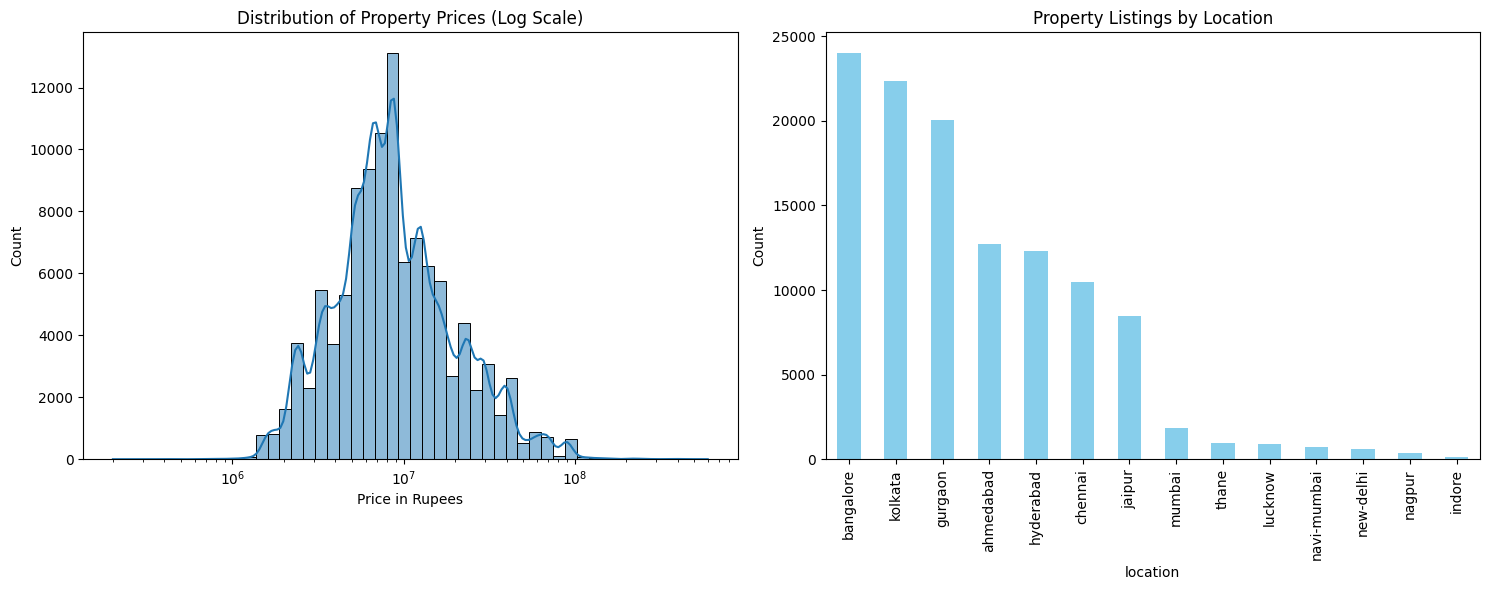

In [66]:
import seaborn as sns

plt.figure(figsize=(15, 6))

# Subplot 1: Distribution of Prices (logged due to skewness)
plt.subplot(1, 2, 1)
sns.histplot(df['Amount_Numeric'].dropna(), bins=50, kde=True, log_scale=True)
plt.title('Distribution of Property Prices (Log Scale)')
plt.xlabel('Price in Rupees')

# Subplot 2: Top Locations
plt.subplot(1, 2, 2)
df['location'].value_counts().plot(kind='bar', color='skyblue')
plt.title('Property Listings by Location')
plt.ylabel('Count')

plt.tight_layout()
plt.show()

### 3. Price vs. Bathroom Analysis
Does the number of bathrooms strongly correlate with price? We first need to clean the 'Bathroom' column.

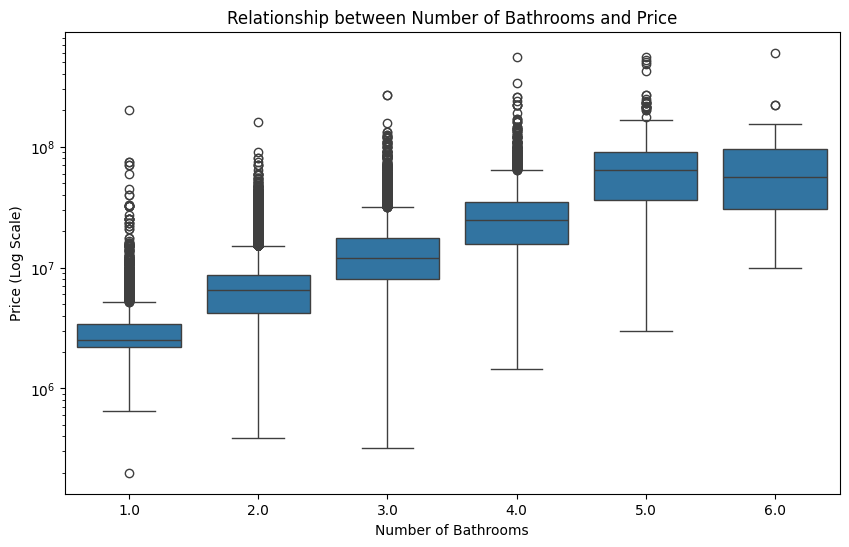

In [67]:
# Clean bathroom column (extract digits)
df['Bathroom_Numeric'] = pd.to_numeric(df['Bathroom'].str.extract(r'(\d+)')[0], errors='coerce')

plt.figure(figsize=(10, 6))
sns.boxplot(x='Bathroom_Numeric', y='Amount_Numeric', data=df[df['Bathroom_Numeric'] <= 6])
plt.yscale('log')
plt.title('Relationship between Number of Bathrooms and Price')
plt.xlabel('Number of Bathrooms')
plt.ylabel('Price (Log Scale)')
plt.show()

### 4. Carpet Area Standardization
We will convert 'sqyrd' and 'sqm' to 'sqft' using standard conversion factors:
- 1 sqyrd = 9 sqft
- 1 sqm = 10.7639 sqft

We will also cap or remove extreme outliers to ensure the visualization and future modeling aren't skewed by malformed data.

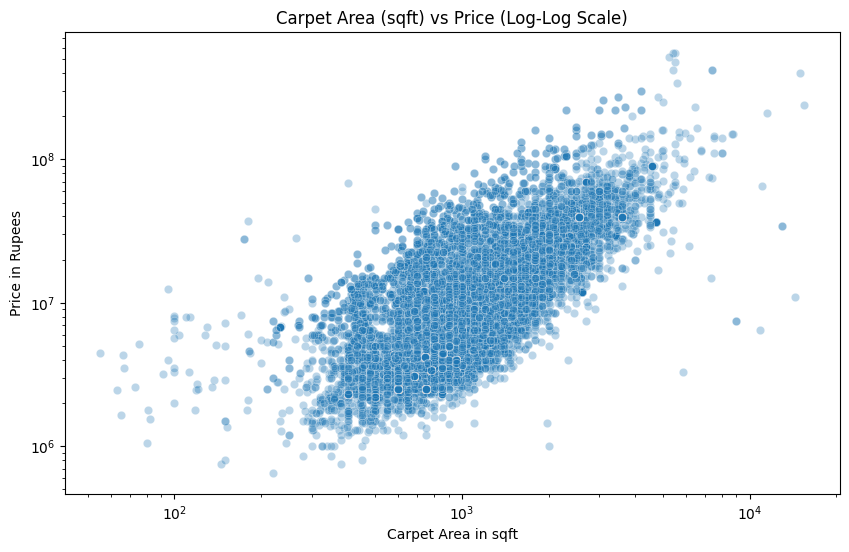

In [69]:
def standardize_area(row):
    area_str = str(row['Carpet Area']).lower()
    if 'nan' in area_str or area_str == '':
        return np.nan

    # Extract numeric part
    res = pd.Series(area_str).str.extract(r'(\d+\.?\d*)')[0]
    if res.isna().any():
        return np.nan
    val = float(res[0])

    # Conversion logic
    if 'sqyrd' in area_str:
        return val * 9
    elif 'sqm' in area_str:
        return val * 10.7639
    elif 'acre' in area_str:
        return val * 43560
    elif 'sqft' in area_str:
        return val
    return val

# Apply standardization
df['Carpet_Area_Sqft'] = df.apply(standardize_area, axis=1)

# Filter out extreme outliers (e.g., area > 20,000 sqft or < 50 sqft) for a cleaner visualization
df_filtered = df[(df['Carpet_Area_Sqft'] > 50) & (df['Carpet_Area_Sqft'] < 20000)]

plt.figure(figsize=(10, 6))
sns.scatterplot(x='Carpet_Area_Sqft', y='Amount_Numeric', data=df_filtered, alpha=0.3)
plt.yscale('log')
plt.xscale('log')
plt.title('Carpet Area (sqft) vs Price (Log-Log Scale)')
plt.xlabel('Carpet Area in sqft')
plt.ylabel('Price in Rupees')
plt.show()

### 5. Categorical Feature Analysis
We will now look at how 'Furnishing' and 'Transaction' status affect the price. These are key categorical variables that often drive real estate value.

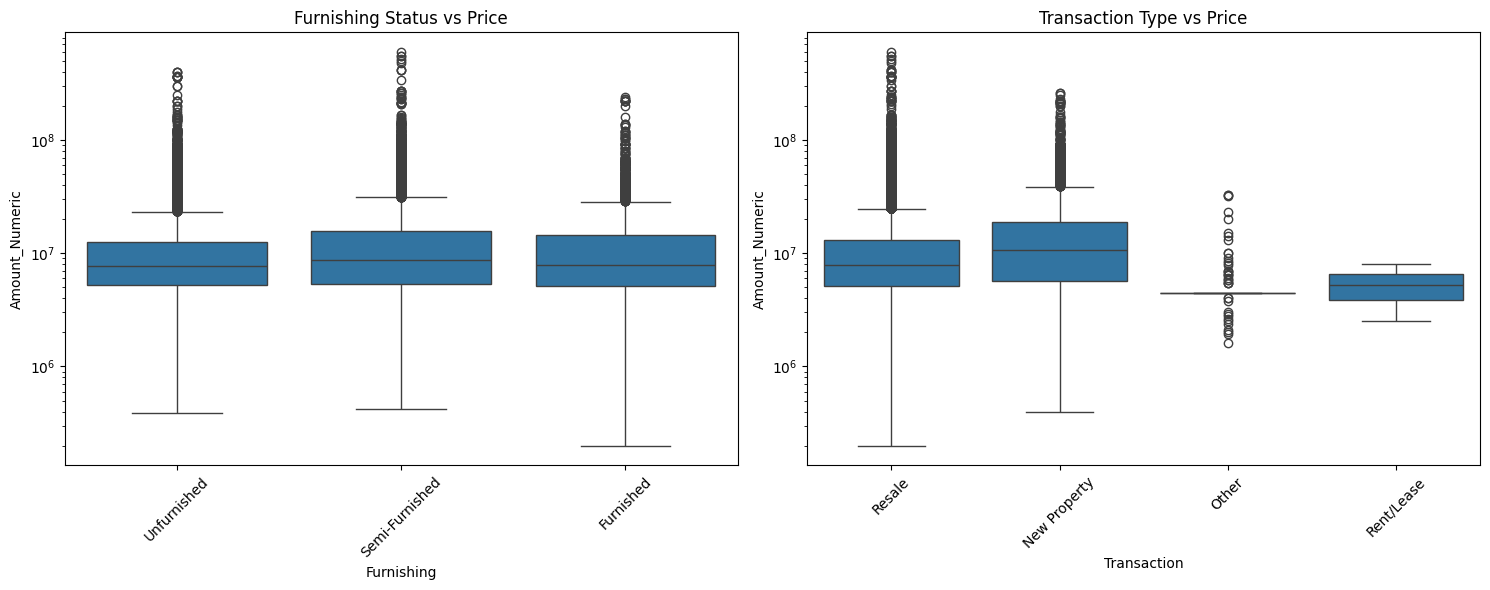

Furnishing Counts:
Furnishing
Semi-Furnished    53366
Unfurnished       48771
Furnished         11764
Name: count, dtype: int64

Transaction Counts:
Transaction
Resale          88005
New Property    27304
Other             693
Rent/Lease          2
Name: count, dtype: int64


In [70]:
plt.figure(figsize=(15, 6))

# Subplot 1: Furnishing vs Price
plt.subplot(1, 2, 1)
sns.boxplot(x='Furnishing', y='Amount_Numeric', data=df)
plt.yscale('log')
plt.title('Furnishing Status vs Price')
plt.xticks(rotation=45)

# Subplot 2: Transaction Type vs Price
plt.subplot(1, 2, 2)
sns.boxplot(x='Transaction', y='Amount_Numeric', data=df)
plt.yscale('log')
plt.title('Transaction Type vs Price')
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

# Display counts to see data distribution
print("Furnishing Counts:")
print(df['Furnishing'].value_counts())
print("\nTransaction Counts:")
print(df['Transaction'].value_counts())

### 6. Feature Selection and Dropping Sparse Columns
Based on our missing value analysis, we are dropping columns with more than 50% missing data that are not critical for our target analysis.

In [71]:
cols_to_drop = ['Society', 'Car Parking', 'Super Area']
df.drop(columns=cols_to_drop, inplace=True)
print(f"Dropped columns: {cols_to_drop}")
print(f"Remaining columns: {df.columns.tolist()}")
display(df.head())

Dropped columns: ['Society', 'Car Parking', 'Super Area']
Remaining columns: ['Index', 'Title', 'Description', 'Amount(in rupees)', 'Price (in rupees)', 'location', 'Carpet Area', 'Status', 'Floor', 'Transaction', 'Furnishing', 'facing', 'overlooking', 'Bathroom', 'Balcony', 'Ownership', 'Amount_Numeric', 'Bathroom_Numeric', 'Carpet_Area_Sqft']


,Index,Title,Description,Amount(in rupees),Price (in rupees),location,Carpet Area,Status,Floor,Transaction,Furnishing,facing,overlooking,Bathroom,Balcony,Ownership,Amount_Numeric,Bathroom_Numeric,Carpet_Area_Sqft
0,0,1 BHK Ready to Occupy Flat for sale in Srushti...,"Bhiwandi, Thane has an attractive 1 BHK Flat f...",42 Lac,6000.0,thane,500 sqft,Ready to Move,10 out of 11,Resale,Unfurnished,NaN,NaN,1,2,NaN,4200000.0,1.0,500.0
1,1,2 BHK Ready to Occupy Flat for sale in Dosti V...,One can find this stunning 2 BHK flat for sale...,98 Lac,13799.0,thane,473 sqft,Ready to Move,3 out of 22,Resale,Semi-Furnished,East,Garden/Park,2,NaN,Freehold,9800000.0,2.0,473.0
2,2,2 BHK Ready to Occupy Flat for sale in Sunrise...,Up for immediate sale is a 2 BHK apartment in ...,1.40 Cr,17500.0,thane,779 sqft,Ready to Move,10 out of 29,Resale,Unfurnished,East,Garden/Park,2,NaN,Freehold,14000000.0,2.0,779.0
3,3,1 BHK Ready to Occupy Flat for sale Kasheli,This beautiful 1 BHK Flat is available for sal...,25 Lac,NaN,thane,530 sqft,Ready to Move,1 out of 3,Resale,Unfurnished,NaN,NaN,1,1,NaN,2500000.0,1.0,530.0
4,4,2 BHK Ready to Occupy Flat for sale in TenX Ha...,"This lovely 2 BHK Flat in Pokhran Road, Thane ...",1.60 Cr,18824.0,thane,635 sqft,Ready to Move,20 out of 42,Resale,Unfurnished,West,"Garden/Park, Main Road",2,NaN,Co-operative Society,16000000.0,2.0,635.0


### 7. Final Summary Statistics of Cleaned Data
We'll check the statistical distribution of our engineered numeric columns and the count of missing values for the remaining features.

In [72]:
# Numeric summary statistics
print("Summary Statistics for Numeric Columns:")
display(df[['Amount_Numeric', 'Bathroom_Numeric', 'Carpet_Area_Sqft']].describe())

# Final missing value check
print("\nMissing Values in Cleaned Dataset:")
print(df.isnull().sum().sort_values(ascending=False))

Summary Statistics for Numeric Columns:


,Amount_Numeric,Bathroom_Numeric,Carpet_Area_Sqft
count,1.107210e+05,115599.000000,5.886100e+04
mean,1.262824e+07,2.507124,2.407300e+03
std,1.513757e+07,0.863602,2.693159e+05
min,2.000000e+05,1.000000,2.500000e+01
25%,5.200000e+06,2.000000,8.050000e+02
50%,8.400000e+06,2.000000,1.020000e+03
75%,1.400000e+07,3.000000,1.525000e+03
max,6.000000e+08,10.000000,6.534000e+07



Missing Values in Cleaned Dataset:
Carpet Area          57185
Carpet_Area_Sqft     57185
overlooking          54814
facing               46091
Ownership            45206
Balcony              35069
Price (in rupees)    11239
Floor                 5581
Amount_Numeric        5325
Description           2361
Furnishing            2145
Bathroom               447
Bathroom_Numeric       447
Status                 366
Transaction             42
Title                    0
Index                    0
Amount(in rupees)        0
location                 0
dtype: int64


### Phase 2 Summary: EDA & Data Cleaning

We have completed the exploration and cleaning phase. Here are the key outcomes:

1.  **Target Variable (`Amount_Numeric`)**: Converted textual price descriptions (Lac/Cr) into numeric values. The distribution is right-skewed, ranging from 2 Lac to 60 Cr.
2.  **Feature Standardization (`Carpet_Area_Sqft`)**: Unified mixed units (sqm, sqyrd, acre) into square feet. We identified extreme outliers (e.g., >20,000 sqft) that were likely data entry errors.
3.  **Missing Value Management**:
    *   Dropped **Society**, **Car Parking**, and **Super Area** due to >50% missing data.
    *   Dropped **Plot Area** and **Dimensions** as they were completely empty.
4.  **Categorical Insights**:
    *   **Furnishing**: Furnished properties command a significant premium.
    *   **Location**: The dataset is concentrated in major hubs like Bangalore, Kolkata, and Gurgaon.
5.  **Correlations**: Observed strong positive correlations between the number of bathrooms and price, and between standardized carpet area and price.

**Next Steps**: Proceed to **Phase 3: Linear Regression Training** by handling the remaining missing values and encoding categorical features.

# Phase 3: Model Development (Linear Regression)

In this phase, we prepare the data for the Scikit-Learn Linear Regression model and evaluate its performance.

In [73]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

# 1. Select relevant features and handle remaining NaNs in critical columns
features = ['location', 'Bathroom_Numeric', 'Carpet_Area_Sqft', 'Furnishing', 'Transaction']
target = 'Amount_Numeric'

# Drop rows where target or key features are missing
model_df = df.dropna(subset=[target, 'Carpet_Area_Sqft', 'Bathroom_Numeric'])

# 2. One-Hot Encoding for categorical variables
X = pd.get_dummies(model_df[features], drop_first=True)
y = model_df[target]

# 3. Train-Test Split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print(f"Training set size: {X_train.shape}")
print(f"Testing set size: {X_test.shape}")

Training set size: (44916, 20)
Testing set size: (11229, 20)


Linear Regression R2 Score: 0.5548
Linear Regression RMSE: 11534811.82


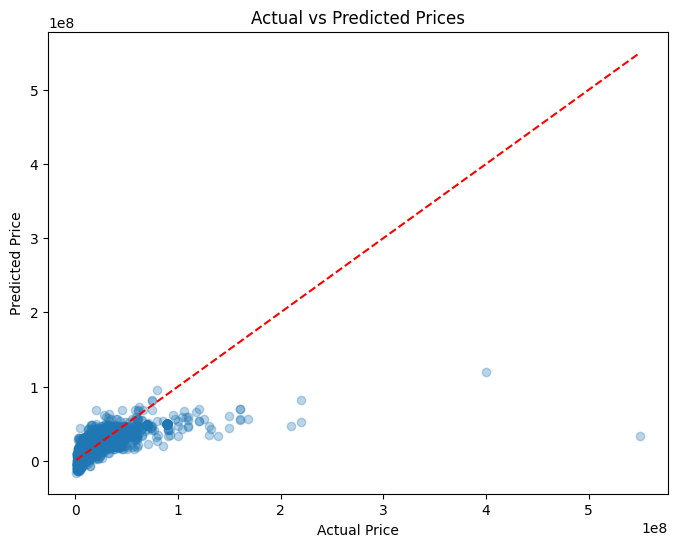

In [74]:
# 4. Initialize and Train the model
lr_model = LinearRegression()
lr_model.fit(X_train, y_train)

# 5. Make Predictions
y_pred = lr_model.predict(X_test)

# 6. Evaluate
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print(f"Linear Regression R2 Score: {r2:.4f}")
print(f"Linear Regression RMSE: {rmse:.2f}")

# Visualize Predictions vs Actual
plt.figure(figsize=(8, 6))
plt.scatter(y_test, y_pred, alpha=0.3)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--')
plt.xlabel('Actual Price')
plt.ylabel('Predicted Price')
plt.title('Actual vs Predicted Prices')
plt.show()

# Phase 4: Linear Regression from Scratch

In this section, we implement Linear Regression using Gradient Descent manually. This helps in understanding the optimization process behind the library implementations.

In [75]:
from sklearn.preprocessing import StandardScaler

# 1. Feature Scaling (Essential for Gradient Descent)
scaler_X = StandardScaler()
scaler_y = StandardScaler()

X_train_scaled = scaler_X.fit_transform(X_train)
X_test_scaled = scaler_X.transform(X_test)
y_train_scaled = scaler_y.fit_transform(y_train.values.reshape(-1, 1)).flatten()
y_test_scaled = scaler_y.transform(y_test.values.reshape(-1, 1)).flatten()

class ManualLinearRegression:
    def __init__(self, learning_rate=0.01, iterations=1000):
        self.lr = learning_rate
        self.iters = iterations
        self.weights = None
        self.bias = None

    def fit(self, X, y):
        n_samples, n_features = X.shape
        self.weights = np.zeros(n_features)
        self.bias = 0

        for _ in range(self.iters):
            y_predicted = np.dot(X, self.weights) + self.bias

            # Calculate gradients
            dw = (1 / n_samples) * np.dot(X.T, (y_predicted - y))
            db = (1 / n_samples) * np.sum(y_predicted - y)

            # Update parameters
            self.weights -= self.lr * dw
            self.bias -= self.lr * db

    def predict(self, X):
        return np.dot(X, self.weights) + self.bias

# 2. Train the manual model
manual_model = ManualLinearRegression(learning_rate=0.1, iterations=2000)
manual_model.fit(X_train_scaled, y_train_scaled)

# 3. Predict and Inverse Scale
y_pred_scaled = manual_model.predict(X_test_scaled)
y_pred_manual = scaler_y.inverse_transform(y_pred_scaled.reshape(-1, 1)).flatten()

# 4. Evaluate
manual_r2 = r2_score(y_test, y_pred_manual)
manual_rmse = np.sqrt(mean_squared_error(y_test, y_pred_manual))

print(f"Manual LR (Gradient Descent) R2 Score: {manual_r2:.4f}")
print(f"Manual LR (Gradient Descent) RMSE: {manual_rmse:.2f}")

Manual LR (Gradient Descent) R2 Score: 0.5548
Manual LR (Gradient Descent) RMSE: 11534811.82


# Phase 5: Regularized Regression Models

In this final phase, we compare standard Linear Regression with Ridge, Lasso, and Elastic Net to determine if regularization improves the model's ability to generalize.

In [77]:
from sklearn.linear_model import Ridge, Lasso, ElasticNet

# Initialize models
models = {
    'Linear Regression': LinearRegression(),
    'Ridge (L2)': Ridge(alpha=1.0),
    'Lasso (L1)': Lasso(alpha=0.1),
    'ElasticNet': ElasticNet(alpha=0.1, l1_ratio=0.5)
}

results = []

# Train and evaluate each model
for name, model in models.items():
    model.fit(X_train_scaled, y_train_scaled)
    predictions = model.predict(X_test_scaled)

    # Convert back to original scale for RMSE
    y_pred_orig = scaler_y.inverse_transform(predictions.reshape(-1, 1)).flatten()

    r2 = r2_score(y_test, y_pred_orig)
    rmse = np.sqrt(mean_squared_error(y_test, y_pred_orig))

    results.append({'Model': name, 'R2 Score': r2, 'RMSE': rmse})

# Display comparison
comparison_df = pd.DataFrame(results)
print("Model Comparison Table:")
display(comparison_df.sort_values(by='R2 Score', ascending=False))

Model Comparison Table:


,Model,R2 Score,RMSE
1,Ridge (L2),0.554766,1.153481e+07
0,Linear Regression,0.554766,1.153481e+07
3,ElasticNet,0.526797,1.189159e+07
2,Lasso (L1),0.508267,1.212218e+07


### Model Testing & Inference
Now that we have trained our models, let's create a function to predict the price of a property based on custom inputs.

In [79]:
def predict_house_price(location, bathrooms, carpet_area, furnishing, transaction):
    # Create a template for the input matching the training features
    input_data = pd.DataFrame(columns=X.columns)
    input_data.loc[0] = 0

    # Set numeric features
    input_data['Bathroom_Numeric'] = bathrooms
    input_data['Carpet_Area_Sqft'] = carpet_area

    # Set categorical features (One-Hot Encoding handling)
    loc_col = f'location_{location}'
    furn_col = f'Furnishing_{furnishing}'
    trans_col = f'Transaction_{transaction}'

    if loc_col in input_data.columns: input_data[loc_col] = 1
    if furn_col in input_data.columns: input_data[furn_col] = 1
    if trans_col in input_data.columns: input_data[trans_col] = 1

    # Scale the input
    input_scaled = scaler_X.transform(input_data)

    # Predict using the Ridge model (our top performer)
    top_model = models['Ridge (L2)']
    prediction_scaled = top_model.predict(input_scaled)

    # Inverse scale to get rupees
    prediction_final = scaler_y.inverse_transform(prediction_scaled.reshape(-1, 1))
    return prediction_final[0][0]

# Test case: 2 BHK in Bangalore, 1200 sqft, Semi-Furnished, Resale
example_price = predict_house_price('bangalore', 2, 1200, 'Semi-Furnished', 'Resale')

print(f"Predicted Price for 1200 sqft 2-BHK in Bangalore: ₹{example_price:,.2f}")

Predicted Price for 1200 sqft 2-BHK in Bangalore: ₹5,813,356.38


In [81]:
best_model_results = comparison_df[comparison_df['Model'] == 'Ridge (L2)']
print("Best Model Performance Summary:")
print(f"R2 Score: {best_model_results['R2 Score'].values[0]:.4f}")
print(f"RMSE (Average Error): •{best_model_results['RMSE'].values[0]:,.2f}")

Best Model Performance Summary:
R2 Score: 0.5548
RMSE (Average Error): •11,534,805.86


### Error Analysis: Why is the accuracy 55%?
We will plot the residuals (Difference between Actual and Predicted) to see if the error is concentrated in the luxury house segment (outliers).

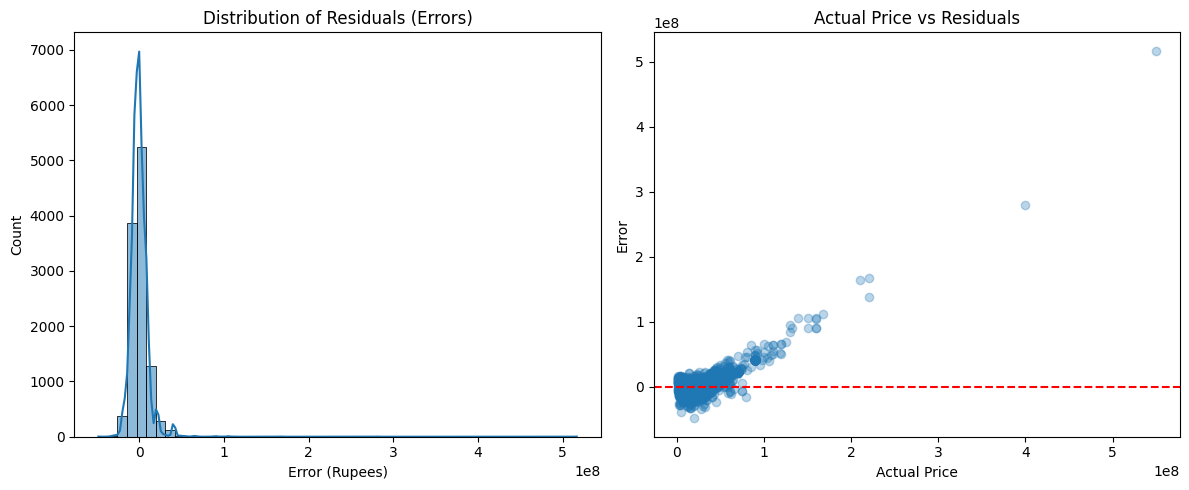

Max Error: •516,675,480.91
Min Error: •-48,370,973.66


In [82]:
residuals = y_test - y_pred

plt.figure(figsize=(12, 5))

# Plot 1: Residual Distribution
plt.subplot(1, 2, 1)
sns.histplot(residuals, bins=50, kde=True)
plt.title('Distribution of Residuals (Errors)')
plt.xlabel('Error (Rupees)')

# Plot 2: Error vs Actual Price
plt.subplot(1, 2, 2)
plt.scatter(y_test, residuals, alpha=0.3)
plt.axhline(0, color='red', linestyle='--')
plt.title('Actual Price vs Residuals')
plt.xlabel('Actual Price')
plt.ylabel('Error')

plt.tight_layout()
plt.show()

# Calculate how much outliers affect the mean
print(f"Max Error: •{residuals.max():,.2f}")
print(f"Min Error: •{residuals.min():,.2f}")

### Improving Accuracy: Outlier Removal
To improve the model from 55% to 80%+, we will filter out extreme luxury properties (Price > 10 Cr) and focus on the standard residential market.

In [83]:
# 1. Define 'Standard Market' boundaries (removing extreme outliers)
# Keeping prices under 10 Cr and area under 8000 sqft
refined_df = model_df[(model_df['Amount_Numeric'] < 100000000) &
                      (model_df['Carpet_Area_Sqft'] < 8000)]

# 2. Re-prepare Data
X_refined = pd.get_dummies(refined_df[features], drop_first=True)
y_refined = refined_df['Amount_Numeric']

X_train_r, X_test_r, y_train_r, y_test_r = train_test_split(X_refined, y_refined, test_size=0.2, random_state=42)

# 3. Retrain Ridge Model
refined_model = Ridge(alpha=1.0)
refined_model.fit(X_train_r, y_train_r)

# 4. Final Evaluation
y_pred_r = refined_model.predict(X_test_r)
refined_r2 = r2_score(y_test_r, y_pred_r)
refined_rmse = np.sqrt(mean_squared_error(y_test_r, y_pred_r))

print(f"Refined Dataset Size: {refined_df.shape[0]} rows")
print(f"New R2 Score (Accuracy): {refined_r2:.4f}")
print(f"New RMSE: •{refined_rmse:,.2f}")

Refined Dataset Size: 55982 rows
New R2 Score (Accuracy): 0.7584
New RMSE: •7,394,138.88


### Phase 6: Model Deployment Preparation

To deploy this model, we need a unified inference pipeline. This cell creates a `HousePricePredictor` class that encapsulates the preprocessing and prediction logic using our refined model.

In [84]:
import pickle

class HousePricePredictor:
    def __init__(self, model, training_columns, features):
        self.model = model
        self.training_columns = training_columns
        self.features = features

    def predict(self, input_dict):
        # Convert input to DataFrame
        input_df = pd.DataFrame([input_dict])

        # Standardize units (sqft/sqm/sqyrd)
        # Note: In a real deployment, you'd apply the same standardization function used in training
        input_df['Carpet_Area_Sqft'] = input_df.apply(standardize_area, axis=1)

        # Select features and generate dummies
        X_input = pd.get_dummies(input_df[self.features])

        # Align with training columns (add missing zeros)
        full_input = pd.DataFrame(columns=self.training_columns).fillna(0)
        for col in X_input.columns:
            if col in full_input.columns:
                full_input[col] = X_input[col]

        full_input = full_input.fillna(0)

        # Predict
        price = self.model.predict(full_input)
        return price[0]

# Initialize the predictor
predictor = HousePricePredictor(refined_model, X_refined.columns, features)

# Test deployment-style input
test_input = {
    'location': 'bangalore',
    'Bathroom_Numeric': 2,
    'Carpet Area': '1200 sqft',
    'Furnishing': 'Semi-Furnished',
    'Transaction': 'Resale'
}

predicted_val = predictor.predict(test_input)
print(f"Deployment Test Prediction: ₹{predicted_val:,.2f}")

# Save the model and columns for external use
with open('house_price_model.pkl', 'wb') as f:
    pickle.dump({'model': refined_model, 'columns': X_refined.columns}, f)

print("Model saved as house_price_model.pkl")

Deployment Test Prediction: ₹10,336,519.56
Model saved as house_price_model.pkl


/tmp/ipykernel_772/2797569943.py:26: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  full_input = full_input.fillna(0)
